<a href="https://colab.research.google.com/github/mhabibier/scikit-learn-cookbook/blob/main/12_Cross_Validation_and_Model_Evaluation_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 12 — Cross-Validation and Model Evaluation Techniques

**scikit-learn Cookbook, Third Edition — John Sukup (Packt, 2025)**  
**Nama:** Muhammad Habibie Rabbani · **Kelas:** TK-47-04

## Tujuan pembelajaran
Memilih skema validasi sesuai struktur data, membedakan skor pemilihan dan generalisasi, memakai GridSearch/RandomizedSearch, serta membaca learning dan validation curves dengan benar.

## Peta reproduksi
Notebook ini mengadaptasi notebook bab utama dan *Exercise Solutions* dari [kode pendamping resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500), commit `c624b1279cf23a83273e806cede15cad0c9e5500`. Penjelasan ditulis ulang dalam Bahasa Indonesia; kode disesuaikan agar dapat dijalankan pada lingkungan yang dicatat di bawah. Penomoran bagian mengikuti alur konsep sumber, bukan nomor halaman PDF. Buku tetap referensi utama untuk membaca uraian lengkap.

| Resep sumber | Bagian |
|---|---|
| KFold dan StratifiedKFold | 1 |
| Leave-One-Out dan nested CV | 2 |
| cross_val_score, cross_validate | 3 |
| GridSearchCV dan RandomizedSearchCV | 4 |
| Learning dan validation curves | 5 |
| Exercises 1–3 | 6–8 |
| Tambahan praktik ML | 9: group dan time split |

## Penyesuaian dan batas reproduksi
StandardScaler ditempatkan dalam Pipeline pada setiap CV. Shuffle dan seed dibuat eksplisit, termasuk `shuffle=True` pada learning_curve. Scoring regresi disebutkan dengan satuan/arah yang jelas. Diabetes memakai `scaled=False` lalu standardisasi dalam fold. Pemilihan metode search dilakukan berdasarkan CV training, bukan test. Skor terbaik search tidak dinyatakan sebagai estimasi generalisasi yang tidak bias.

## Cara menjalankan
Jalankan **Restart Kernel → Run All** dari atas ke bawah. Setiap notebook mandiri. Gunakan Python 3.12 dan paket dalam `requirements.txt`; versi yang benar-benar dipakai tampil di sel pertama. Dataset tersedia melalui scikit-learn atau generator sintetis; tidak memerlukan unduhan data tambahan setelah paket terpasang.

Untuk Google Colab: unggah `.ipynb`, instal versi paket yang diperlukan bila berbeda, lalu **Restart session → Run all**. Pengujian paket ini dilakukan dengan proses IPython baru per notebook, bukan melalui antarmuka Colab.

In [ ]:
%matplotlib inline
import sys, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score

SEED = 2024
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 115, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 4)
print({'Python': platform.python_version(), 'scikit-learn': sklearn.__version__,
       'NumPy': np.__version__, 'pandas': pd.__version__, 'seed': SEED})

def audit_numeric(X, y=None, name='data'):
    frame = pd.DataFrame(X)
    print(name, {'shape': frame.shape, 'missing': int(frame.isna().sum().sum()),
                 'duplicate_rows': int(frame.duplicated().sum()),
                 'all_finite': bool(np.isfinite(frame.to_numpy(dtype=float)).all())})
    if y is not None and np.asarray(y).ndim == 1:
        display(pd.Series(y).value_counts().sort_index().rename('jumlah').to_frame())

def report(y_true, y_pred, names=None):
    result = classification_report(y_true, y_pred, target_names=names, output_dict=True, zero_division=0)
    overall_accuracy = result.pop('accuracy', None)
    display(pd.DataFrame(result).T)
    if overall_accuracy is not None:
        print(f'Overall accuracy: {overall_accuracy:.4f} (n={len(y_true)})')

def metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0)}

{'Python': '3.12.14', 'scikit-learn': '1.8.0', 'NumPy': '2.3.5', 'pandas': '2.2.3', 'seed': 2024}


## 1. KFold dan stratifikasi
Train/validation/test mempunyai peran berbeda: training mempelajari parameter, validation memilih konfigurasi, test menilai model/prosedur yang telah dipilih. K-fold CV memutar K validation-fold sehingga setiap pengamatan menjadi validation sekali. Rata-rata $\bar{s}=\frac1K\sum_k s_k$ meringkas skor fold, tetapi model yang dilatih pada tiap fold berbeda.

KFold biasa tidak menjaga proporsi kelas. StratifiedKFold menjaga distribusi kelas mendekati keseluruhan sehingga fold tidak kekurangan kelas minoritas. Stratifikasi membantu stabilitas metrik, **bukan** solusi semua masalah representativitas dan bukan pengganti group/time split. Standardisasi harus fit ulang pada setiap training-fold.

Demo sumber memakai 500 sampel, 10 fitur (8 informatif, 2 redundan). Kita tampilkan komposisi kelas dan skor tiap fold. Karena subset training antar-fold tumpang tindih, simpangan baku skor fold bukan standard error dari K pengamatan independen; jangan langsung mengklaim confidence interval formal.

In [ ]:
from sklearn.datasets import make_classification, load_diabetes
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (KFold, LeaveOneOut, cross_val_score, RandomizedSearchCV,
    learning_curve, validation_curve, GroupKFold, TimeSeriesSplit)
from scipy.stats import loguniform
from sklearn.metrics import root_mean_squared_error, r2_score

X,y=make_classification(n_samples=500,n_features=10,n_informative=8,n_redundant=2,n_classes=2,random_state=SEED)
audit_numeric(X,y,'CV demonstration')
logistic=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED))
fold_rows=[]
for name,splitter in [('KFold',KFold(5,shuffle=True,random_state=SEED)),
                       ('StratifiedKFold',StratifiedKFold(5,shuffle=True,random_state=SEED))]:
    for fold,(tr,va) in enumerate(splitter.split(X,y),1):
        assert not set(tr)&set(va)
        m=clone(logistic).fit(X[tr],y[tr]); p=m.predict(X[va])
        fold_rows.append({'splitter':name,'fold':fold,'train_n':len(tr),'validation_n':len(va),
                          'positive_fraction':y[va].mean(),'accuracy':accuracy_score(y[va],p)})
folds=pd.DataFrame(fold_rows); display(folds)
display(folds.groupby('splitter').accuracy.agg(['mean','std']))

CV demonstration {'shape': (500, 10), 'missing': 0, 'duplicate_rows': 0, 'all_finite': True}


,jumlah
0,250
1,250


,splitter,fold,train_n,validation_n,positive_fraction,accuracy
0,KFold,1,400,100,0.52,0.71
1,KFold,2,400,100,0.47,0.72
2,KFold,3,400,100,0.54,0.88
3,KFold,4,400,100,0.51,0.73
4,KFold,5,400,100,0.46,0.75
5,StratifiedKFold,1,400,100,0.50,0.79
6,StratifiedKFold,2,400,100,0.50,0.77
7,StratifiedKFold,3,400,100,0.50,0.76
8,StratifiedKFold,4,400,100,0.50,0.76
9,StratifiedKFold,5,400,100,0.50,0.75


,mean,std
splitter,,
KFold,0.758,0.0698
StratifiedKFold,0.766,0.0152


## 2. Leave-One-Out dan nested CV
**LOOCV** melatih n model dengan n−1 observasi training dan satu validation. Keuntungannya memakai hampir seluruh data pada setiap fit; biayanya n kali training dan estimasi dapat memiliki varians tinggi. R² tidak terdefinisi untuk validation satu sampel, sehingga gunakan squared error tiap titik lalu rata-ratakan. Scikit-learn memakai `neg_mean_squared_error` agar semua search memaksimalkan skor; tandanya dibalik saat dilaporkan.

**Nested CV** memisahkan pemilihan hyperparameter (inner CV) dari penilaian prosedur pencarian (outer CV). Setiap outer-fold menjalankan grid sendiri tanpa melihat outer-validation. Skor outer menilai keseluruhan proses pemilihan, bukan sekadar satu konfigurasi yang kebetulan menang pada seluruh data.

Diabetes dipakai untuk regresi. Standardisasi di setiap fold membuat penalti Ridge terdefinisi konsisten terhadap skala training. LOOCV alpha tetap dan nested search menjawab pertanyaan berbeda, sehingga angka keduanya tidak boleh diperlakukan sebagai kompetisi dengan protokol identik.

In [ ]:
d=load_diabetes(scaled=False); Dx,Dy=d.data,d.target
ridge=make_pipeline(StandardScaler(),Ridge(alpha=1))
loo_scores=cross_val_score(ridge,Dx,Dy,cv=LeaveOneOut(),scoring='neg_mean_squared_error',n_jobs=1,error_score='raise')
print('LOOCV fixed alpha=1: mean MSE =',-loo_scores.mean(),'; RMSE =',np.sqrt(-loo_scores.mean()),'; fits =',len(loo_scores))
inner=KFold(5,shuffle=True,random_state=SEED)
outer=KFold(5,shuffle=True,random_state=2025)
ridge_search=GridSearchCV(ridge,{'ridge__alpha':[.01,.1,1,10,100]},cv=inner,
    scoring='neg_mean_squared_error',n_jobs=1,error_score='raise')
nested=cross_validate(ridge_search,Dx,Dy,cv=outer,scoring={'MSE':'neg_mean_squared_error','R2':'r2'},
    return_estimator=True,n_jobs=1,error_score='raise')
nested_table=pd.DataFrame({'outer_fold':range(1,6),'RMSE':np.sqrt(-nested['test_MSE']),
    'R2':nested['test_R2'],'chosen_alpha':[m.best_params_['ridge__alpha'] for m in nested['estimator']]})
display(nested_table); print('Mean outer RMSE:',nested_table.RMSE.mean(),'Mean outer R2:',nested_table.R2.mean())

LOOCV fixed alpha=1: mean MSE = 3000.027955790463 ; RMSE = 54.77251095020624 ; fits = 442
Mean outer RMSE: 54.57317029043554 Mean outer R2: 0.4901209854433991


,outer_fold,RMSE,R2,chosen_alpha
0,1,56.2996,0.4942,10.0
1,2,56.4675,0.4596,10.0
2,3,56.7629,0.5107,10.0
3,4,54.8252,0.4818,10.0
4,5,48.5107,0.5042,0.1


## 3. cross_val_score, cross_validate, dan metrik yang relevan
`cross_val_score` mengembalikan satu metrik per fold. `cross_validate` dapat mencatat beberapa metrik sekaligus, waktu fitting, dan bila diminta estimasi training. Untuk kelas tidak seimbang 70/30, bandingkan accuracy dengan baseline mayoritas serta precision, recall, F1 dan balanced accuracy.

Precision/recall/F1 default biner menganggap **label 1 sebagai positif** pada dataset sintetis ini. Label tersebut berbeda dari malignant=0 di Breast Cancer pada bab sebelumnya. Sebanyak 30% data disisihkan lebih dahulu untuk test akhir Bagian 4; semua demonstrasi CV di bagian ini hanya memakai 70% training. `best_score_` dari grid adalah skor **seleksi internal**, belum skor test independen.

In [ ]:
Xi,yi=make_classification(n_samples=500,n_features=10,weights=[.7,.3],random_state=SEED)
Xt,Xv,yt,yv=train_test_split(Xi,yi,test_size=.3,stratify=yi,random_state=SEED)
cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
single=cross_val_score(clone(logistic),Xt,yt,cv=cv,scoring='accuracy',n_jobs=1)
multi=cross_validate(clone(logistic),Xt,yt,cv=cv,scoring=['accuracy','balanced_accuracy','precision','recall','f1'],return_train_score=True,n_jobs=1)
summary=pd.DataFrame({k:v for k,v in multi.items() if k.startswith('test_')}).agg(['mean','std']).T
display(summary)
dummy=cross_val_score(DummyClassifier(strategy='most_frequent'),Xt,yt,cv=cv,scoring='accuracy')
print('Accuracy CV model:',single.mean(),'Dummy:',dummy.mean())
select_only=GridSearchCV(clone(logistic),{'logisticregression__C':[.01,.1,1,10]},cv=cv,scoring='accuracy',n_jobs=1).fit(Xt,yt)
print('Best internal selection score (bukan test independen):',select_only.best_score_,select_only.best_params_)

Accuracy CV model: 0.9085714285714287 Dummy: 0.7
Best internal selection score (bukan test independen): 0.9114285714285716 {'logisticregression__C': 10}


,mean,std
test_accuracy,0.9086,0.0359
test_balanced_accuracy,0.8748,0.0361
test_precision,0.8974,0.0888
test_recall,0.7905,0.0426
test_f1,0.8395,0.0580


## 4. Grid Search, Randomized Search, dan test akhir
Grid menguji semua kombinasi daftar kandidat. Randomized search mengambil sejumlah kandidat dari distribusi yang ditentukan. Untuk C yang meliputi beberapa orde magnitudo, **log-uniform** memberi peluang yang sebanding pada rentang logaritmik, bukan membiaskan sampel ke angka besar seperti uniform linear.

Kedua search menggunakan split training/test 70/30 dan fold training yang sama. Metode dengan skor CV tertinggi dipilih; aturan tie memilih grid ditetapkan terlebih dahulu. Hanya model terpilih dievaluasi pada test akhir. Test tidak digunakan untuk menambah jumlah iterasi random search atau memperlebar grid. Bila proses pemilihan diulang berkali-kali, nested CV atau test baru diperlukan.

In [ ]:
# Gunakan pembagian yang sudah dibuat sebelum demonstrasi CV Bagian 3.
grid=GridSearchCV(clone(logistic),{'logisticregression__C':[.001,.01,.1,1,10,100]},cv=cv,scoring='accuracy',n_jobs=1,error_score='raise').fit(Xt,yt)
random=RandomizedSearchCV(clone(logistic),{'logisticregression__C':loguniform(1e-3,1e2)},n_iter=10,cv=cv,
    scoring='accuracy',random_state=SEED,n_jobs=1,error_score='raise').fit(Xt,yt)
display(pd.DataFrame([{'search':name,'CV accuracy':m.best_score_,'best C':m.best_params_['logisticregression__C'],
    'candidates':len(m.cv_results_['params'])} for name,m in [('Grid',grid),('Randomized',random)]]))
selected_name,selected=('Grid',grid) if grid.best_score_>=random.best_score_ else ('Randomized',random)
final_pred=selected.predict(Xv)
print('Dipilih melalui CV:',selected_name,'; final holdout:',metrics(yv,final_pred)); report(yv,final_pred)

Dipilih melalui CV: Randomized ; final holdout: {'accuracy': 0.9266666666666666, 'balanced_accuracy': 0.8904761904761904, 'macro_f1': 0.9083893176392205}
Overall accuracy: 0.9267 (n=150)


,search,CV accuracy,best C,candidates
0,Grid,0.9114,10.0000,6
1,Randomized,0.9171,0.1744,10


,precision,recall,f1-score,support
0,0.9196,0.9810,0.9493,105.0
1,0.9474,0.8000,0.8675,45.0
macro avg,0.9335,0.8905,0.9084,150.0
weighted avg,0.9280,0.9267,0.9248,150.0


## 5. Learning curve dan validation curve
Learning curve mengubah jumlah training samples, lalu membandingkan skor training dengan validation. Skor keduanya rendah dan berdekatan dapat menunjukkan underfitting atau sinyal data lemah. Gap besar dapat menunjukkan overfitting; menambah data kadang membantu. Kurva tidak membuktikan diagnosis tunggal karena noise, shift, dan pilihan metrik juga memengaruhi hasil.

Validation curve mengubah satu hyperparameter dengan dataset/protokol tetap. C kecil meningkatkan regularisasi; C besar menguranginya. Kurva berikut menggunakan pool sintetis terpisah 1.000×20, sesuai resep, bukan test akhir Bagian 4. `shuffle=True` dipasang agar `random_state` pada learning_curve benar-benar digunakan. Pita ±1 SD fold menunjukkan variasi, bukan confidence interval formal.

{'last_train_accuracy': np.float64(0.89825), 'last_validation_accuracy': np.float64(0.893), 'last_gap': np.float64(0.005249999999999977)}


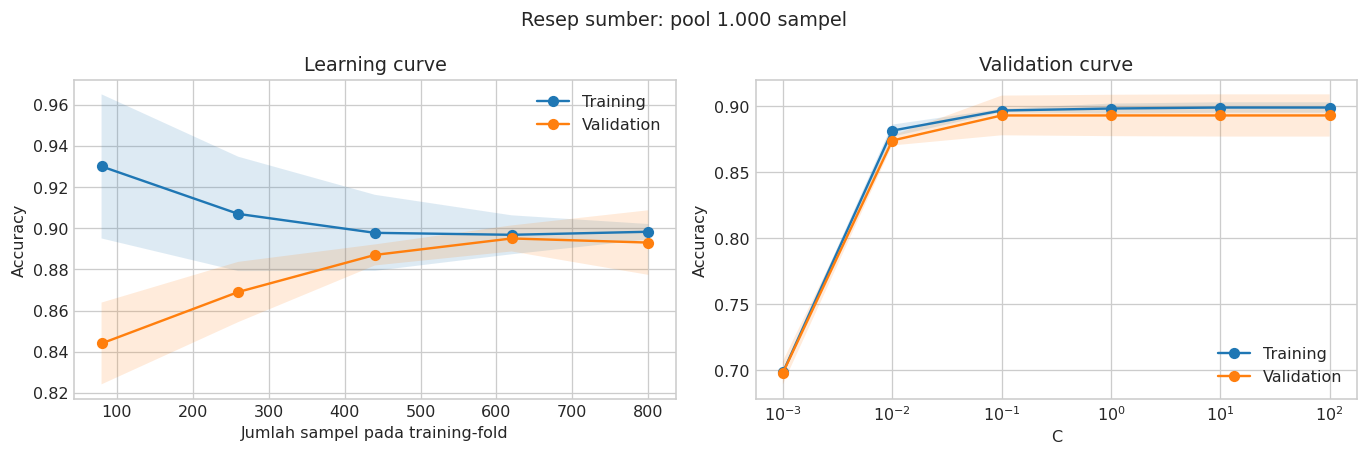

In [ ]:
def plot_learning_validation(X,y,title):
    splits=StratifiedKFold(5,shuffle=True,random_state=SEED)
    sizes,train,valid=learning_curve(clone(logistic),X,y,cv=splits,scoring='accuracy',
        train_sizes=np.linspace(.1,1,5),shuffle=True,random_state=SEED,n_jobs=1,error_score='raise')
    values=np.logspace(-3,2,6)
    tr,va=validation_curve(clone(logistic),X,y,param_name='logisticregression__C',param_range=values,
        cv=splits,scoring='accuracy',n_jobs=1,error_score='raise')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for matrix,label in [(train,'Training'),(valid,'Validation')]:
        axes[0].plot(sizes,matrix.mean(axis=1),'o-',label=label)
        axes[0].fill_between(sizes,matrix.mean(axis=1)-matrix.std(axis=1),matrix.mean(axis=1)+matrix.std(axis=1),alpha=.15)
    for matrix,label in [(tr,'Training'),(va,'Validation')]:
        axes[1].semilogx(values,matrix.mean(axis=1),'o-',label=label)
        axes[1].fill_between(values,matrix.mean(axis=1)-matrix.std(axis=1),matrix.mean(axis=1)+matrix.std(axis=1),alpha=.15)
    axes[0].set(xlabel='Jumlah sampel pada training-fold',ylabel='Accuracy',title='Learning curve')
    axes[1].set(xlabel='C',ylabel='Accuracy',title='Validation curve')
    for ax in axes: ax.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return {'last_train_accuracy':train[-1].mean(),'last_validation_accuracy':valid[-1].mean(),
            'last_gap':train[-1].mean()-valid[-1].mean()}

Xc,yc=make_classification(n_samples=1000,n_features=20,weights=[.7,.3],random_state=SEED)
curve_diagnostic=plot_learning_validation(Xc,yc,'Resep sumber: pool 1.000 sampel')
print(curve_diagnostic)

## 6. Latihan 1 — multi-metric CV logistic regression
Mengikuti solusi latihan, generator 500×10 menggunakan jumlah fitur informatif default, sehingga dataset berbeda dari Bagian 1 yang menetapkan delapan fitur informatif. Karena itu hasilnya tidak harus sama. Setiap fold melatih Pipeline baru; ringkasan memuat mean dan SD accuracy, precision, recall dan F1.

In [ ]:
Xe,ye=make_classification(n_samples=500,n_features=10,random_state=SEED)
ex1=cross_validate(clone(logistic),Xe,ye,cv=cv,scoring=['accuracy','precision','recall','f1'],n_jobs=1,error_score='raise')
display(pd.DataFrame({k:v for k,v in ex1.items() if k.startswith('test_')}).agg(['mean','std']).T)

,mean,std
test_accuracy,0.8980,0.0217
test_precision,0.9032,0.0349
test_recall,0.8906,0.0344
test_f1,0.8962,0.0213


## 7. Latihan 2 — SVC grid
Latihan sumber menggunakan kernel linear/RBF dan C=0,1/1/10. Tambahan scaler ada di dalam Pipeline. Scoring utama ditetapkan accuracy karena generator relatif seimbang. Laporan per kelas test tetap dicetak. Pemilihan memakai training-CV dan refit otomatis pada seluruh training.

In [ ]:
Et,Ev,et,ev=train_test_split(Xe,ye,test_size=.3,stratify=ye,random_state=SEED)
ex2=GridSearchCV(make_pipeline(StandardScaler(),SVC()),{'svc__C':[.1,1,10],'svc__kernel':['linear','rbf']},
    cv=cv,scoring='accuracy',n_jobs=1,error_score='raise').fit(Et,et)
print('Latihan 2 best params:',ex2.best_params_,'CV:',ex2.best_score_)
print('Final test:',metrics(ev,ex2.predict(Ev))); report(ev,ex2.predict(Ev))

Latihan 2 best params: {'svc__C': 0.1, 'svc__kernel': 'rbf'} CV: 0.917142857142857
Final test: {'accuracy': 0.9066666666666666, 'balanced_accuracy': 0.9068278805120911, 'macro_f1': 0.9066666666666666}
Overall accuracy: 0.9067 (n=150)


,precision,recall,f1-score,support
0,0.9189,0.8947,0.9067,76.0
1,0.8947,0.9189,0.9067,74.0
macro avg,0.9068,0.9068,0.9067,150.0
weighted avg,0.9070,0.9067,0.9067,150.0


## 8. Latihan 3 — kurva generalisasi pada pool latihan
Kurva latihan dihitung menggunakan **training subset Et saja**, agar test Ev dari Latihan 2 tetap berperan sebagai penilaian akhir. Kurva membantu merumuskan eksperimen berikutnya; jika hasilnya dipakai mengubah desain setelah melihat skor test sebelumnya, lakukan evaluasi konfirmatori pada data baru dan jangan mengklaim skor test lama tetap independen.

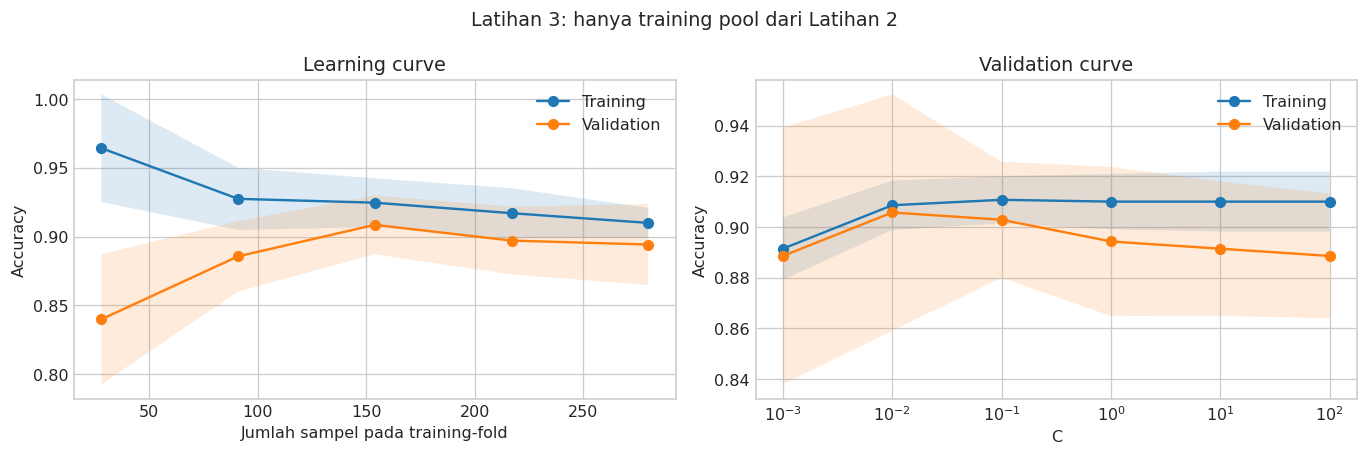

**Analisis kurva:** pada ukuran training terbesar, mean train = 0.910, mean validation = 0.894, gap = 0.016. Baca bersama variasi fold; gap kecil saja tidak menjamin model cukup baik.

In [ ]:
ex3=plot_learning_validation(Et,et,'Latihan 3: hanya training pool dari Latihan 2')
display(Markdown(f"**Analisis kurva:** pada ukuran training terbesar, mean train = {ex3['last_train_accuracy']:.3f}, "
 f"mean validation = {ex3['last_validation_accuracy']:.3f}, gap = {ex3['last_gap']:.3f}. "
 'Baca bersama variasi fold; gap kecil saja tidak menjamin model cukup baik.'))

## 9. Tambahan — kapan random CV tidak tepat?
Random CV mengasumsikan observasi cukup independen dan distribusi training/validation relevan. Bila satu orang menghasilkan banyak baris, **GroupKFold** menjaga semua baris orang itu pada satu sisi. Untuk data waktu, **TimeSeriesSplit** melatih pada masa lalu dan memvalidasi pada masa berikutnya; `gap` dapat mengurangi kedekatan langsung, tetapi harus mempertimbangkan horizon target dan window fitur.

Contoh berikut memeriksa batas split dengan assert. Ini demonstrasi mekanisme pemisahan, bukan benchmark algoritma baru. Scaling/feature engineering pada data berkelompok atau temporal tetap harus fit dalam training setiap split.

In [ ]:
groups=np.repeat(np.arange(20),5); group_X=np.zeros((100,2)); group_y=np.tile([0,1,0,1,0],20)
group_rows=[]
for fold,(tr,va) in enumerate(GroupKFold(5).split(group_X,group_y,groups),1):
    overlap=set(groups[tr])&set(groups[va]); assert not overlap
    group_rows.append({'fold':fold,'train_groups':len(set(groups[tr])),'validation_groups':len(set(groups[va])),'overlap':len(overlap)})
display(pd.DataFrame(group_rows))
time_rows=[]
for fold,(tr,va) in enumerate(TimeSeriesSplit(n_splits=4,gap=2).split(np.arange(50)),1):
    assert tr.max()<va.min()
    time_rows.append({'fold':fold,'last_training_index':tr.max(),'first_validation_index':va.min(),'validation_n':len(va)})
display(pd.DataFrame(time_rows))

,fold,train_groups,validation_groups,overlap
0,1,16,4,0
1,2,16,4,0
2,3,16,4,0
3,4,16,4,0
4,5,16,4,0


,fold,last_training_index,first_validation_index,validation_n
0,1,7,10,10
1,2,17,20,10
2,3,27,30,10
3,4,37,40,10


## Ringkasan chapter
CV mengukur performa melalui data yang tidak dipakai fitting pada fold tersebut. Tuning dan evaluasi prosedur membutuhkan pemisahan yang berbeda, sehingga nested CV atau holdout akhir penting. Metrik harus sesuai target dan imbalance. Learning/validation curves memberi petunjuk, sedangkan group/time split menjaga validitas ketika data tidak independen.

## Refleksi untuk dikerjakan sendiri
1. Apa perbedaan `best_score_` GridSearchCV dan skor outer-fold nested CV?
2. Mengapa scaler yang fit sebelum CV dapat membocorkan informasi?
3. Mengapa R² tidak tepat untuk satu validation sample LOOCV?
4. Untuk data sensor parkir per detik, mengapa random split berpotensi terlalu optimistis?

## Referensi dan atribusi
- John Sukup. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Kode pendamping Chapter 12 dan solusi latihan: [repository resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500).
- [Cross-validation](https://scikit-learn.org/1.8/modules/cross_validation.html).
- [Tuning hyperparameters](https://scikit-learn.org/1.8/modules/grid_search.html).
- [Learning and validation curves](https://scikit-learn.org/1.8/modules/learning_curve.html).
- Kode sumber pendamping berlisensi MIT; teks lisensi dipertahankan pada `THIRD_PARTY_NOTICES.md`. Penjelasan, koreksi metodologi, dan eksperimen tambahan pada notebook ini merupakan adaptasi belajar berbantuan AI. Baca, jalankan ulang, dan tulis refleksi pribadi sebelum menyerahkan tugas; jangan menyatakan bagian berbantuan AI sebagai pekerjaan mandiri tanpa mengikuti kebijakan kelas.